# Task 2.4: a better readout

**Answer.**
- **Circuit.** In the full pumped circuit, without the rotating-wave approximation, photon pairing only works if the pump is retuned by $\Delta_p/2\pi=-23$ MHz to undo Stark shifts.
- **Pulse shape.** A readout drive at the buffer's ringing frequency $\omega_r$ (Task 2.3) cuts the readout error from 1.12% to 0.65% in 2 µs at $\alpha=2.1$. The gain survives a 50% efficient detector.
- **Optimizer.** A gradient optimizer through the simulator rediscovers resonant driving on its own, but adds little beyond it.

**Figure of merit.** For a readout of length $T$ followed by 2.5 µs of free decay,

$$\mathrm{SNR}=\kappa_b\int|\langle b\rangle_+-\langle b\rangle_-|^2dt,\qquad \epsilon_{\rm ro}=\tfrac12\mathrm{erfc}\sqrt{\eta\,\mathrm{SNR}/2}+P_{\rm flip},$$

where $P_{\rm flip}$ is the drive-induced bit flip probability and $\eta$ the detector efficiency ($\eta=1$ unless stated). A stronger drive raises SNR and $P_{\rm flip}$ together, so each pulse shape has an optimal strength; only the shape changes the trade-off.

In [1]:
from pathlib import Path
import sys, io
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F
show = lambda name, w=1000: display(Image(filename=str(ROOT / "figures/s2" / f"{name}.png"), width=w))

## 1. Does pairing survive the real circuit?

The simplified model keeps only $g_2(a^2b^\dagger+\mathrm{h.c.})$. Expanding the pumped ATS Hamiltonian (`research/s2/rwa_terms.py`) shows that this is the only resonant term, and that it needs pump strength $\epsilon_p=0.037$. We then simulate the full circuit Hamiltonian without the rotating-wave approximation (`research/s2/circuit_sim.py`, 150 ns, no loss) and compare the memory photon number with the simplified model.

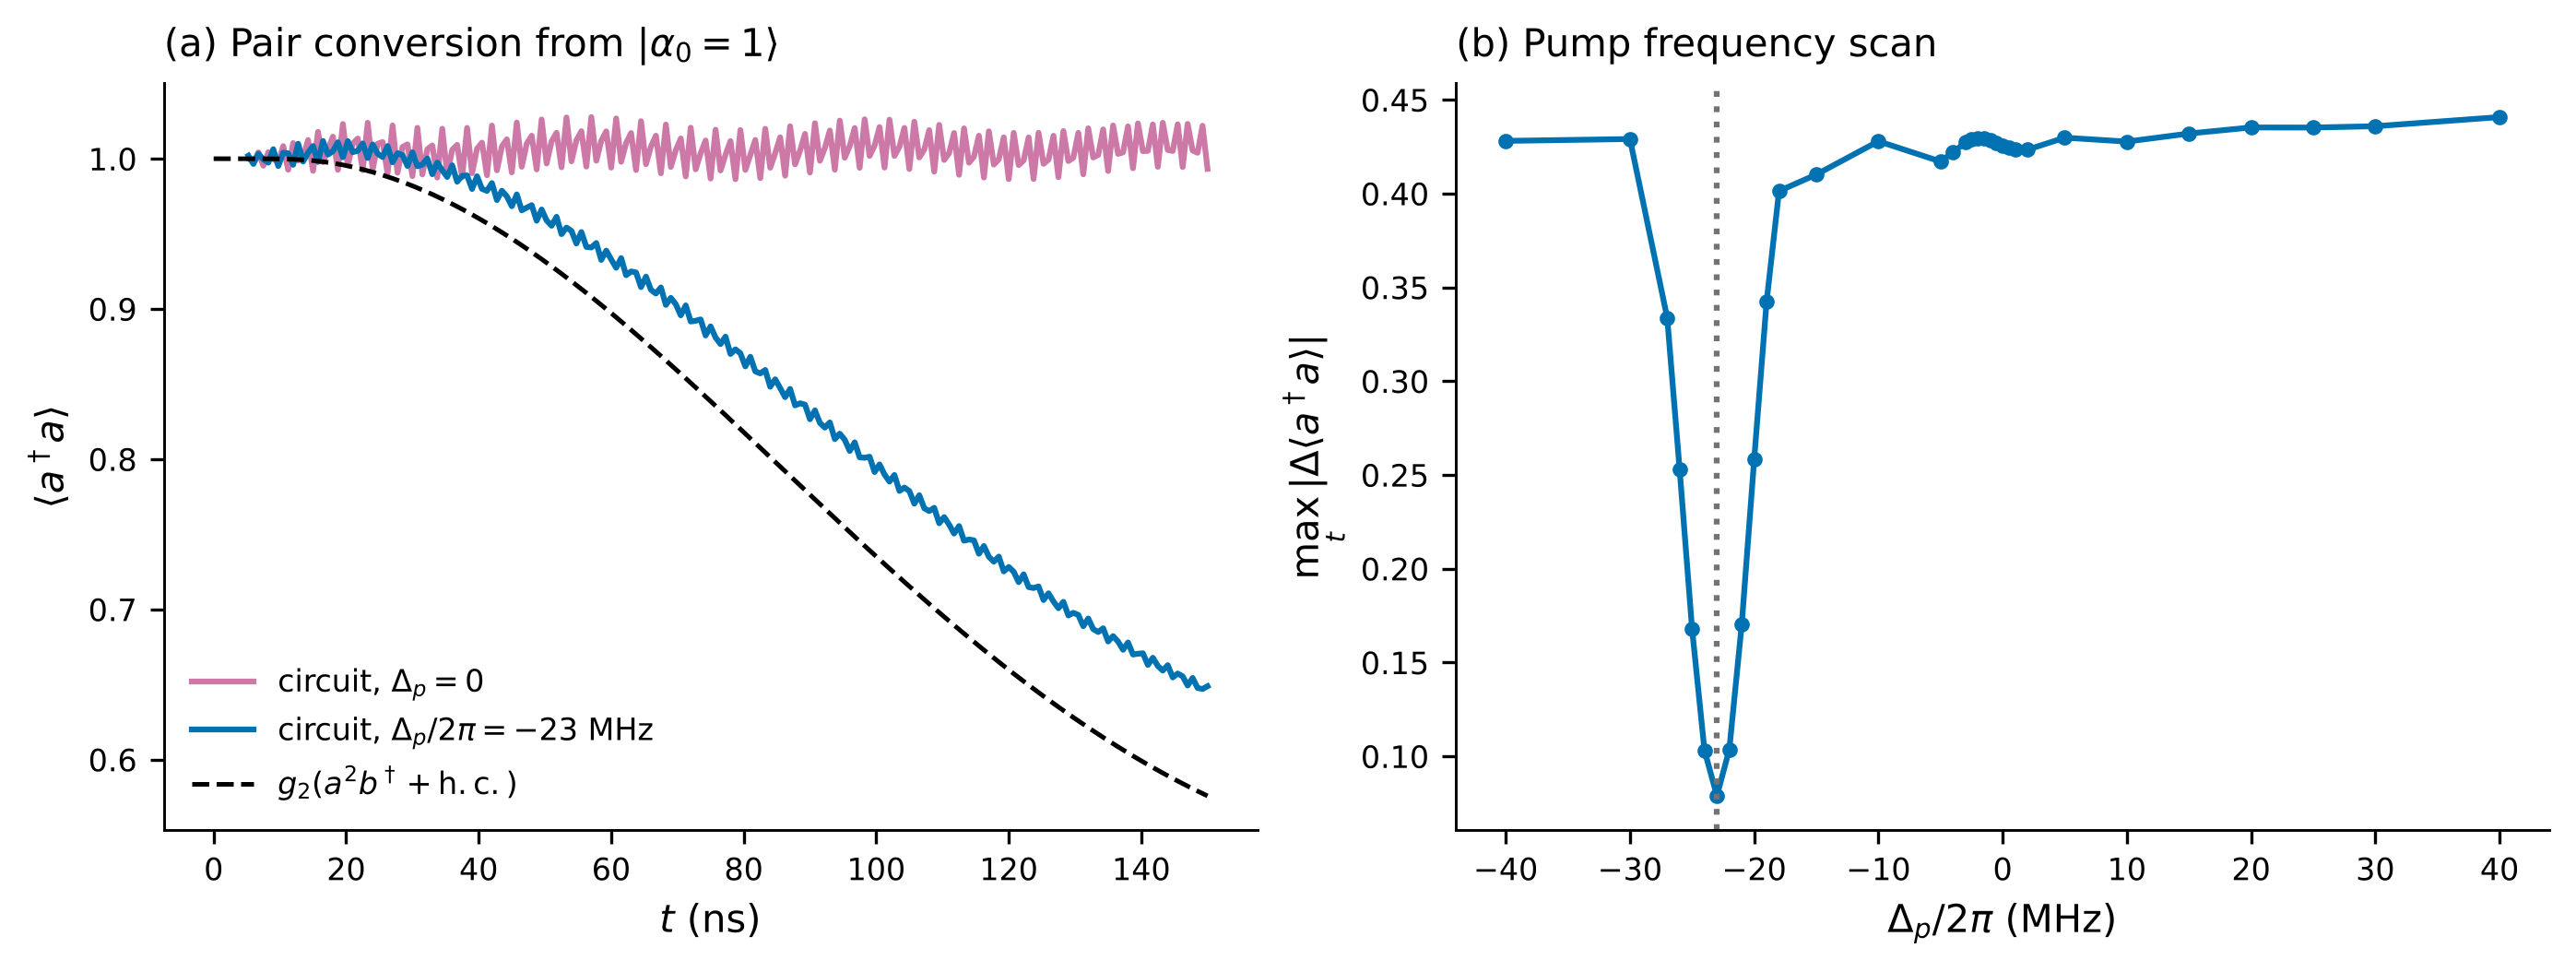

max |Δ⟨a†a⟩| (6 ns average): 0.43 at Δp = 0, 0.07 at Δp/2π = −23 MHz


In [2]:
with redirect_stdout(io.StringIO()):
    F.circuit_check()
show("task_2_4_circuit")
d0, d23 = (F.load(f"circuit_na14_nb6_T0.15_dp{dp}.json")[0] for dp in (0, -23))
print(f"max |Δ⟨a†a⟩| (6 ns average): {d0['max_abs_diff_na_averaged']:.2f} at Δp = 0, "
      f"{d23['max_abs_diff_na_averaged']:.2f} at Δp/2π = −23 MHz")

**Circuit check.** (a) $\langle a^\dagger a\rangle$ from the coherent state $\lvert\alpha_0=1\rangle$ with the buffer empty, at truncation $14\times6$, with a 6 ns average to hide the pump ripple. At the nominal pump frequency (pink), pairs do not convert. Retuned by $-23$ MHz (blue), the circuit follows the simplified model (dashed) but about 15% more slowly, so the effective $g_2$ is slightly smaller. (b) Largest photon number mismatch against pump detuning ($10\times4$); the sharp dip marks the corrected pump. The result is the same at $12\times5$.

## 2. Which pulse shape reads out best?

We compare three drive shapes $\epsilon_Z(t)$ at $\alpha=2.1$, each at peak $0.5$, $0.75$ and $1\,g_2$ for $T=2$ µs (`research/s2/pulse_eval.py`, $30\times8$):
- a square pulse;
- a cosine at the ringing frequency, $\cos\omega_r t$ with $\omega_r=\sqrt{(2g_2\alpha)^2-\kappa_b^2/16}$;
- its bang-bang version, $\mathrm{sgn}(\cos\omega_r t)$.

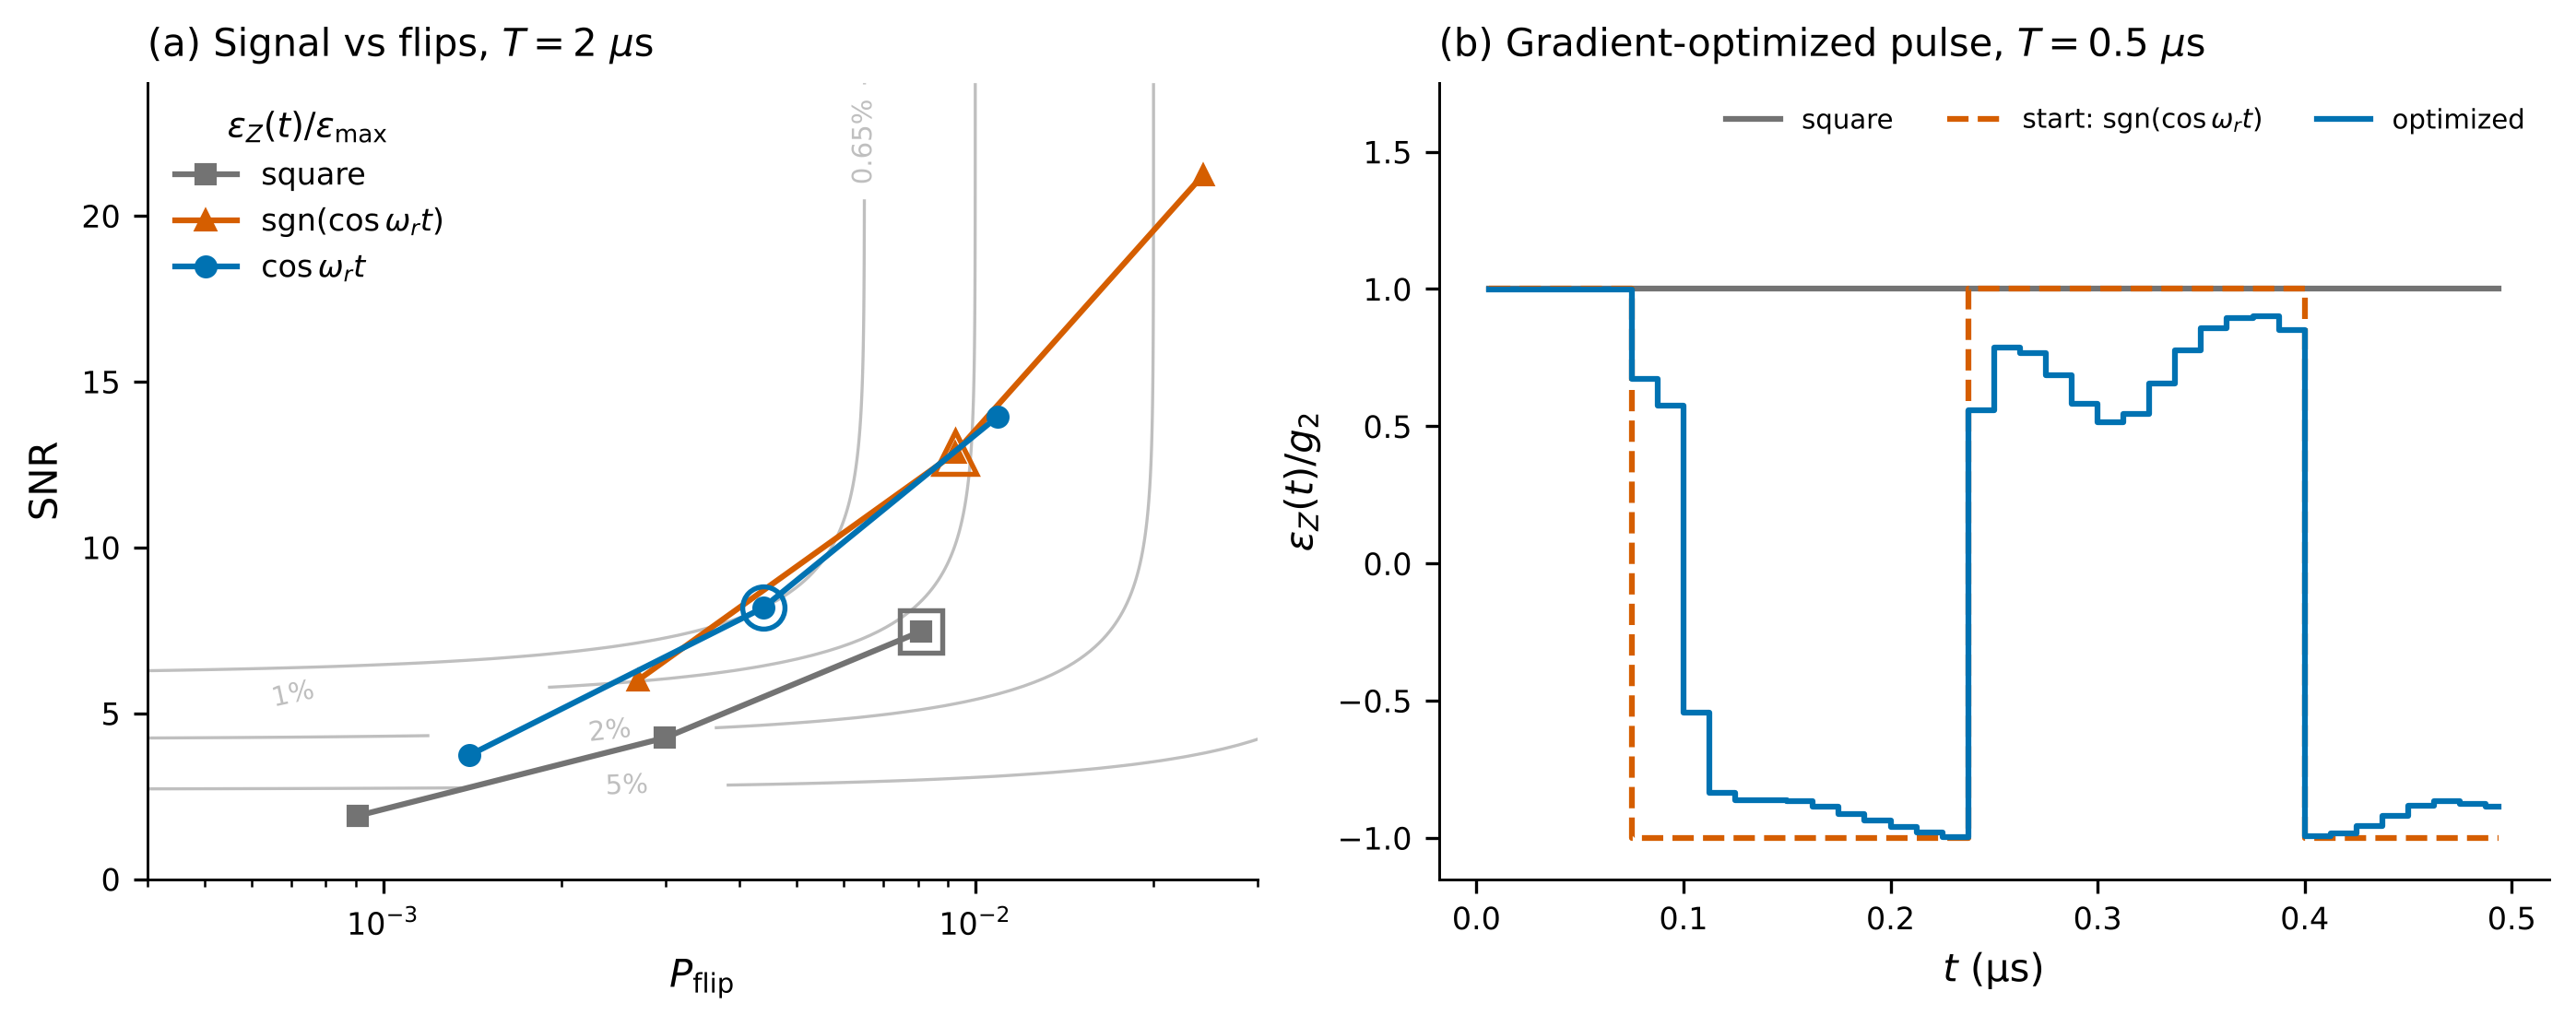

pulse,best peak (g₂),SNR,P_flip,ε_ro (η = 1),ε_ro (η = 0.5)
square,1,7.5,8.1e-03,1.12%,3.48%
sgn(cos ω_r t),0.75,12.8,9.2e-03,0.94%,1.49%
cos ω_r t,0.75,8.2,4.4e-03,0.65%,1.50%


In [3]:
with redirect_stdout(io.StringIO()):
    F.better_readout()
show("task_2_4_better_readout")
ps = F.load("pulse_a2.10_30x8_T2_peak.json")[0]
names = {"square": "square", "bang": "sgn(cos ω_r t)", "res": "cos ω_r t"}
rows = []
for f, name in names.items():
    fam = [r for r in ps["rows"] if r["family"] == f]
    b1 = min(fam, key=F.readout_error)
    b5 = min(fam, key=lambda r: F.readout_error(r, 0.5))
    rows.append({"pulse": name, "best peak (g₂)": f"{b1['level']:g}", "SNR": f"{b1['snr']:.1f}",
                 "P_flip": f"{b1['p_flip']:.1e}", "ε_ro (η = 1)": f"{100 * F.readout_error(b1):.2f}%",
                 "ε_ro (η = 0.5)": f"{100 * F.readout_error(b5, 0.5):.2f}%"})
display(pd.DataFrame(rows).style.hide(axis="index"))

**Pulse comparison.** (a) SNR against $P_{\rm flip}$ for each shape. Points run left to right through peak drives of 0.5, 0.75 and $1\,g_2$; the large open marker is each shape's lowest error. Gray curves are contours of $\epsilon_{\rm ro}$. Resonant shapes reach higher SNR for the same flips, because they drive the 3.2 MHz memory–buffer oscillator in step and the buffer amplifies the signal. (b) The optimized pulse (Section 3) against its bang-bang start and a square pulse.

**How robust is this?** With a 50% efficient detector, both resonant shapes give 1.5% against 3.5% for the square pulse. The resonant advantage holds, but the two resonant shapes tie. The square pulse's best peak sits at the edge of the scan; extrapolating with $\mathrm{SNR},P_{\rm flip}\propto\epsilon_Z^2$ moves its optimum to about 1.1%, so the 1.7× gain stands.

## 3. Can an optimizer do better?

`research/s2/pulse_opt.py` differentiates through the full simulation (`jax.grad` through dynamiqs). It shapes a 40-bin pulse with $|\epsilon_Z|\le\epsilon_{\max}$, starting from $\mathrm{sgn}(\cos\omega_r t)$, and maximizes $\mathrm{SNR}-\mu P_{\rm flip}$, where $\mu$ is the square pulse's SNR per flip. That objective is signal per flip, not $\epsilon_{\rm ro}$. Runs use 0.5 to 1 µs windows, which is what the compute allowed.

In [4]:
opt = sorted((d for d in F.load("opt_*.json") if not d.get("partial") and d["nb"] >= 8),
             key=lambda d: (d["alpha"], d["T"], d["peak"]))
spf = lambda x: x["snr"] / x["p_flip"]
display(pd.DataFrame([{
    "α": d["alpha"], "T (µs)": d["T"], "ε_max (g₂)": d["peak"],
    "SNR/P_flip vs square": f"{spf(d['best']) / spf(d['square']):.2f}",
    "SNR/P_flip vs start": f"{spf(d['best']) / spf(d['history'][0]):.2f}",
    "ε_ro square": f"{100 * F.readout_error(d['square']):.1f}%",
    "ε_ro start": f"{100 * F.readout_error(d['history'][0]):.1f}%",
    "ε_ro optimized": f"{100 * F.readout_error(d['best']):.1f}%",
} for d in opt]).style.hide(axis="index").format({"α": "{:g}", "T (µs)": "{:g}", "ε_max (g₂)": "{:g}"}))

α,T (µs),ε_max (g₂),SNR/P_flip vs square,SNR/P_flip vs start,ε_ro square,ε_ro start,ε_ro optimized
1.4,0.5,0.5,1.55,1.02,18.4%,20.7%,18.7%
1.4,0.5,1,1.66,1.02,13.3%,10.0%,9.4%
1.4,1,0.5,1.59,1.02,13.7%,12.2%,10.9%
1.8,0.5,0.5,1.36,1.03,20.6%,19.1%,17.7%
1.8,0.5,1,1.71,1.14,6.5%,5.3%,5.1%
1.8,1,0.5,1.32,0.98,13.1%,8.0%,6.5%
2.1,0.5,0.5,1.26,1.05,23.3%,17.4%,18.5%
2.1,0.5,1,1.56,1.16,7.5%,3.5%,4.4%
2.1,1,0.5,1.30,1.11,16.1%,7.0%,9.8%


**What the optimizer found.** In all 9 converged settings it beats a square pulse by 1.26 to 1.71× in signal per flip. Most of that comes from the resonant start: over its start it gains only 0.98 to 1.16×. Its pulse keeps the sign changes at the ringing period (panel b). Measured by $\epsilon_{\rm ro}$, it improves on its start at $\alpha\le1.8$ (6 of 9 settings) but not at $\alpha=2.1$. There, the objective trades signal for fewer flips, while in these short windows the error is dominated by misreads. An optimizer aimed directly at $\epsilon_{\rm ro}$ over 2 µs is the natural next step.

**Result.**
- The real circuit needs its pump retuned by $-23$ MHz, or pairing switches off.
- Driving at the ringing frequency is the effective lever: $\epsilon_{\rm ro}$ falls from 1.12% to 0.65% in 2 µs ($\eta=1$), or from 3.5% to 1.5% at $\eta=0.5$.
- Gradient optimization rediscovers resonant driving and improves on it by at most 16% in signal per flip.

Limits: the circuit simulation covers 150 ns without loss; $\epsilon_{\rm ro}$ assumes an ideal matched filter; optimizer runs stop at 1 µs.